# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jiaxian Wang, Sam Edwards, Kamal Sangameswaran

**Date:** 11/16/2026

In [2]:
# Your Phase 1 solution to the problem goes here.
#Q1
import pandas as pd
heart_failure = pd.read_csv("heart_failure_clinical_records_dataset.csv")
display(heart_failure.head())
print(heart_failure.shape)
heart_failure.info()
print(heart_failure.isna().sum())
print(heart_failure.duplicated().sum())
display(heart_failure.describe())

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


(299, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
age     

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


The dataset contains 299 observations and 13 variables. All variables are numeric, and there is no missing values or duplicate rows. Although some variables contain extreme values, they may represent valid clinical observations. Therefore, no additional cleaning was necessary.

Tree train accuracy: 0.9163179916317992
Linear train accuracy: 0.8493723849372385
Tree test accuracy: 0.6833333333333333
Tree confusion matrix:
[[28  7]
 [12 13]]
Linear test accuracy: 0.7833333333333333
Linear confusion matrix:
[[33  2]
 [11 14]]


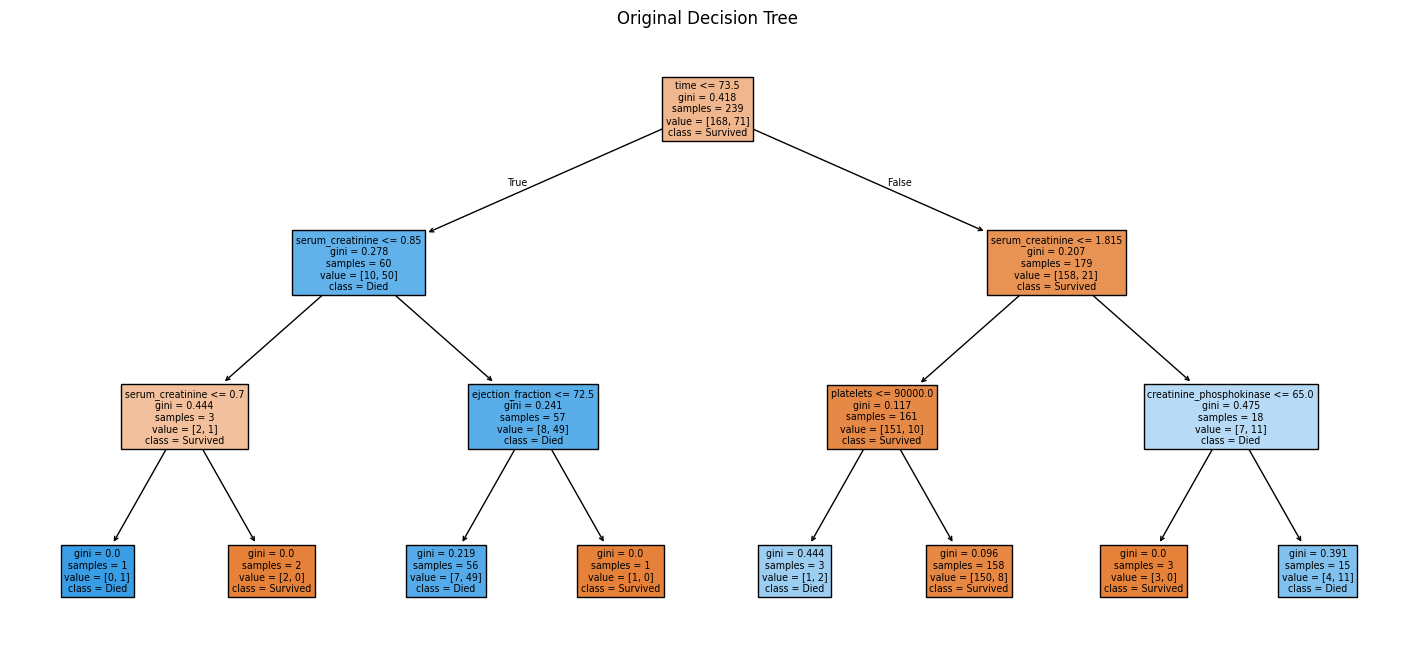

In [7]:
#Q2
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix

X = heart_failure.drop(columns="DEATH_EVENT")
y = heart_failure["DEATH_EVENT"]

seed = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed)

tree = DecisionTreeClassifier(max_depth=3, random_state=seed)
linear = LogisticRegression(max_iter=10000, solver="liblinear")

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)


tree_class = tree.predict(X_test)
linear_class = linear.predict(X_test)

tree_pred = tree.predict_proba(X_test)[:, 1]
linear_pred = linear.predict_proba(X_test)[:, 1]

print("Tree train accuracy:", accuracy_score(y_train, tree.predict(X_train)))
print("Linear train accuracy:", accuracy_score(y_train, linear.predict(X_train)))
print("Tree test accuracy:", accuracy_score(y_test, tree_class))
print("Tree confusion matrix:")
print(confusion_matrix(y_test, tree_class))
print("Linear test accuracy:", accuracy_score(y_test, linear_class))
print("Linear confusion matrix:")
print(confusion_matrix(y_test, linear_class))

plt.figure(figsize=(18, 8))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["Survived", "Died"],
    filled=True)
plt.title("Original Decision Tree")
plt.show()

Seed: 10
Tree accuracy: 0.7833333333333333
Linear accuracy: 0.8166666666666667
Tree depth: 3
Tree leaves: 8


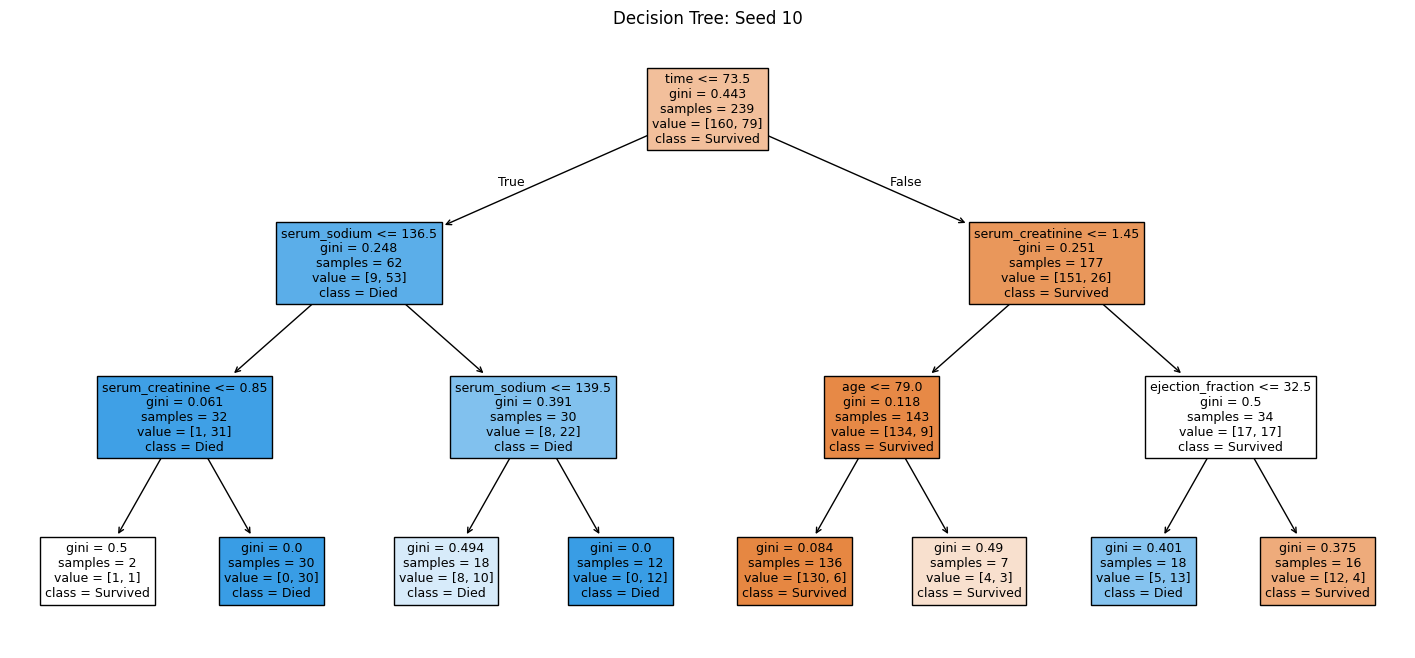

Seed: 20
Tree accuracy: 0.8333333333333334
Linear accuracy: 0.7833333333333333
Tree depth: 3
Tree leaves: 8


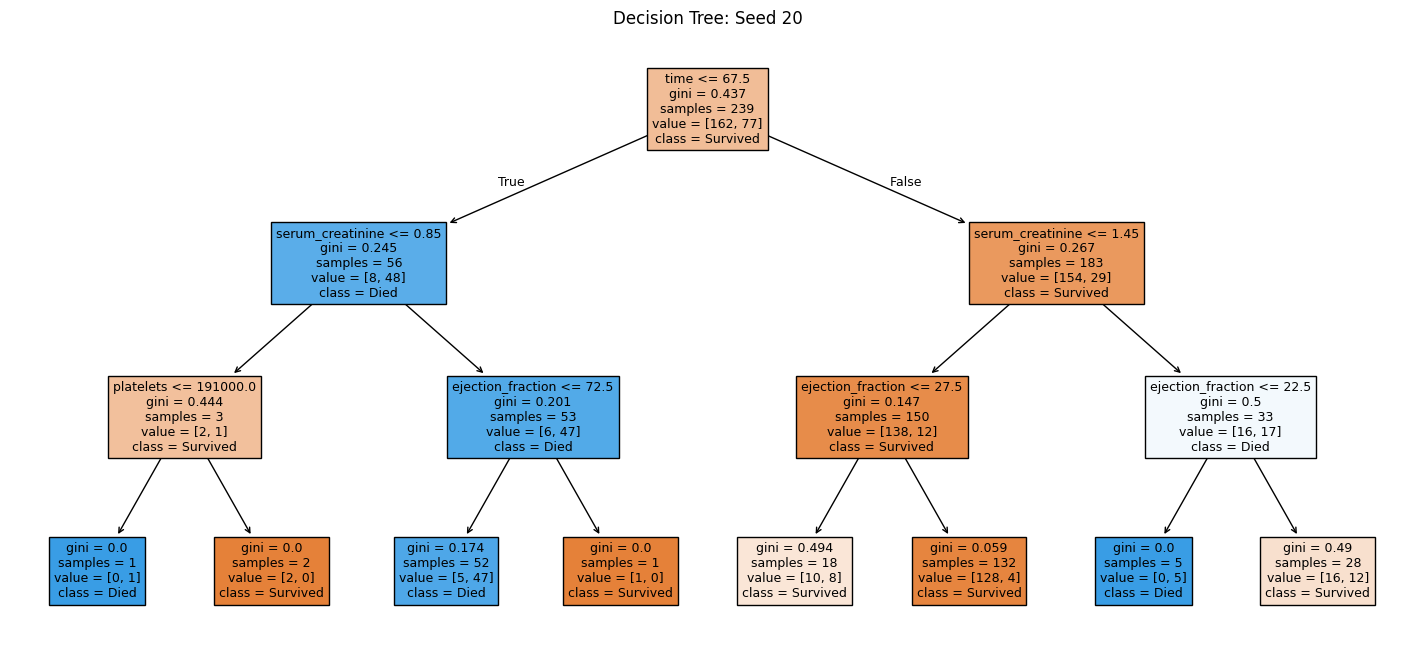

Seed: 30
Tree accuracy: 0.75
Linear accuracy: 0.7666666666666667
Tree depth: 3
Tree leaves: 8


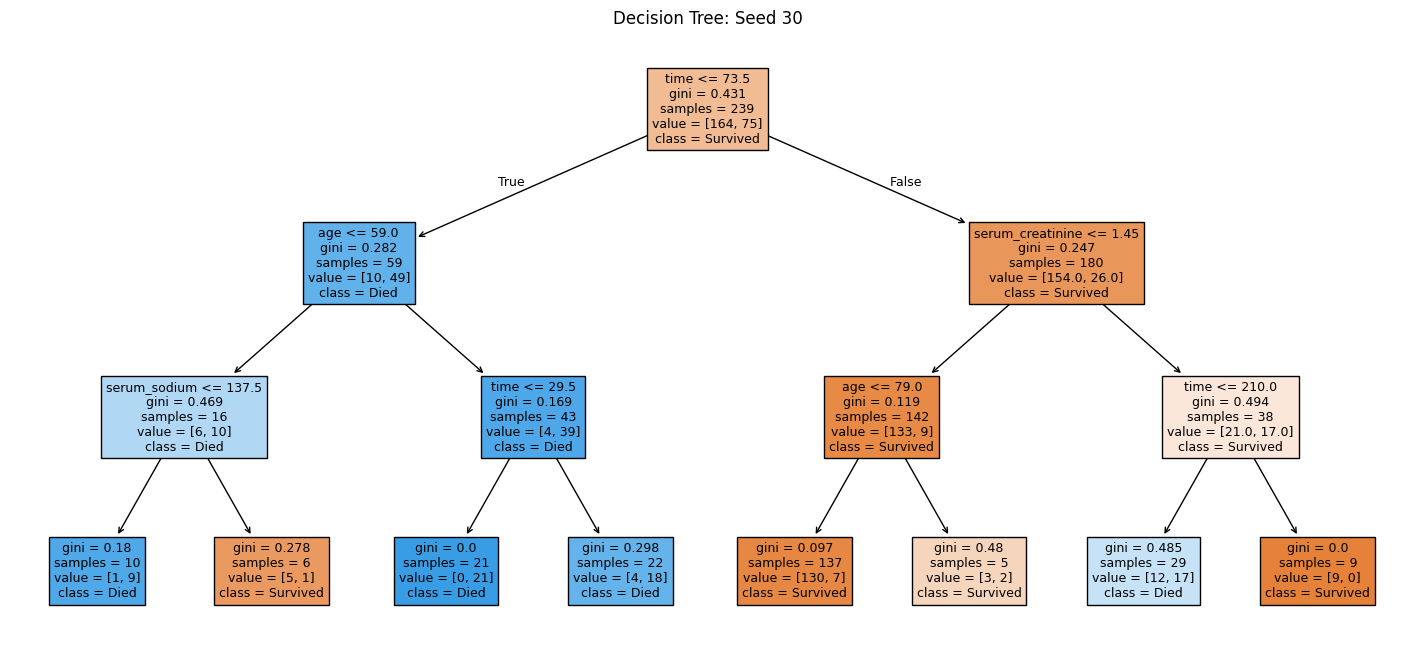

Seed: 40
Tree accuracy: 0.7666666666666667
Linear accuracy: 0.85
Tree depth: 3
Tree leaves: 7


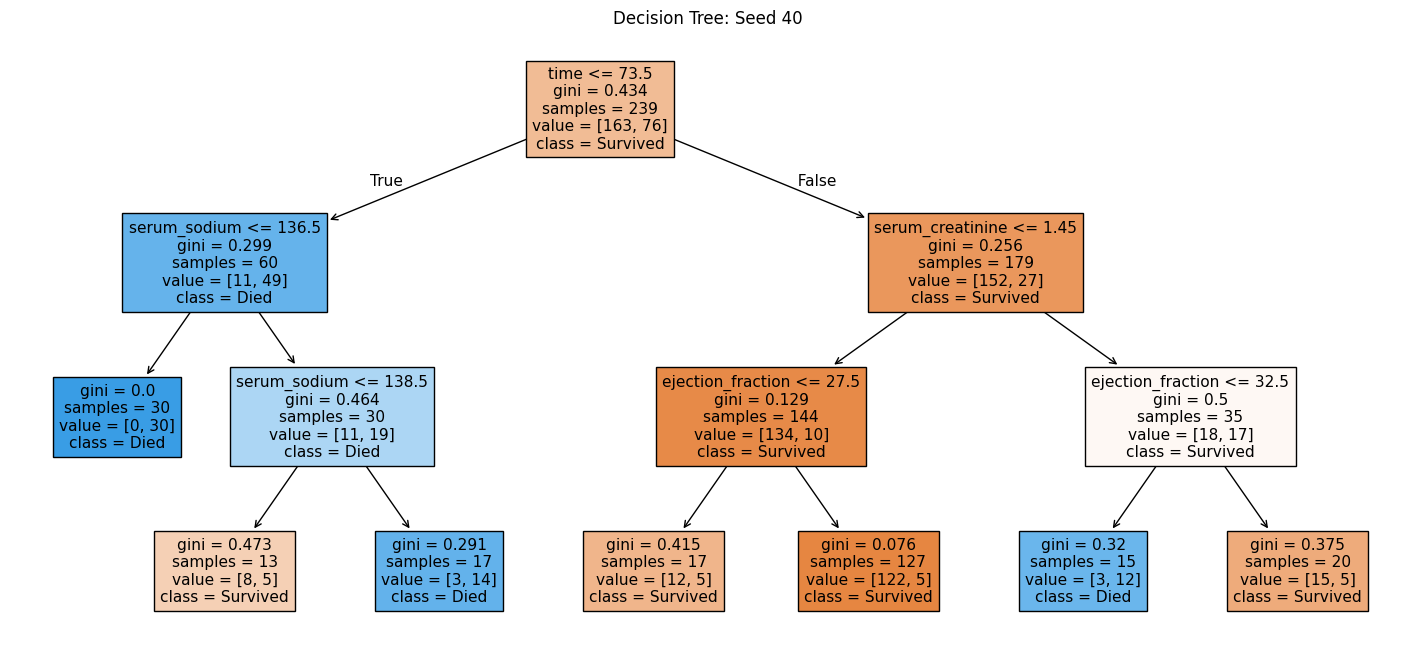

,10,20,30,40,Original
age,0.034271,0.060580,0.041518,0.027415,0.037790
anaemia,0.000411,0.000287,0.000997,0.000404,-0.000055
creatinine_phosphokinase,0.000081,0.000110,-0.000016,0.000173,0.000087
diabetes,0.000358,0.000609,0.000549,0.000276,0.000487
ejection_fraction,-0.041816,-0.088194,-0.044258,-0.033627,-0.037431
high_blood_pressure,-0.000070,-0.000416,-0.000252,-0.000262,-0.000357
platelets,-0.000003,-0.000002,-0.000002,-0.000002,-0.000002
serum_creatinine,0.005383,0.011202,0.007508,0.004517,0.005911
serum_sodium,0.012790,0.008084,0.007463,0.008184,0.006652
sex,-0.000255,-0.001621,-0.001049,-0.000384,-0.000692


In [8]:
#Q3
seeds = [10, 20, 30, 40]

trees = {}
linears = {}
tree_preds = {}
linear_preds = {}
coefficients = {}
for s in seeds:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=s)
    t = DecisionTreeClassifier(max_depth=3, random_state=s)
    l = LogisticRegression(max_iter=10000, solver="liblinear")

    t.fit(X_tr, y_tr)
    l.fit(X_tr, y_tr)

    trees[s] = t
    linears[s] = l
    tree_preds[s] = t.predict_proba(X_test)[:, 1]
    linear_preds[s] = l.predict_proba(X_test)[:, 1]
    coefficients[s] = l.coef_[0]

    print("Seed:", s)
    print("Tree accuracy:", accuracy_score(y_te, t.predict(X_te)))
    print("Linear accuracy:", accuracy_score(y_te, l.predict(X_te)))
    print("Tree depth:", t.get_depth())
    print("Tree leaves:", t.get_n_leaves())

    plt.figure(figsize=(18, 8))
    plot_tree(
        t,
        feature_names=X.columns,
        class_names=["Survived", "Died"],
        filled=True)
    plt.title(f"Decision Tree: Seed {s}")
    plt.show()

coef_df = pd.DataFrame(coefficients, index=X.columns)
coef_df["Original"] = linear.coef_[0]
display(coef_df)

The decision trees show pretty noticeable differences across the train/test splits. All four trees use time as the first splitting feature, but the threshold changes from 73.5 to 67.5 for seed 20. The later splits vary more across different seeds. For example, seed 10 splits on serum_sodium on the left side, while seed 20 uses serum_creatinine and seed 30 uses age. All four trees have a depth of 3, but their splitting features and thresholds differ, and their test accuracies range from 75.0% to 83.3%. In contrast, the logistic regression coefficients are relatively stable across different train/test splits. Most coefficients remain the same signs, including age, ejection_fraction, serum_creatinine, and time. For example, the coefficient for time ranges from  -0.018 to -0.022, while the coefficient for age ranges from 0.027 to 0.061. Although some coefficients vary in magnitude, their overall patterns remain similar across the different seeds.

Q4:
The logistic regression coefficients vary by different amounts across train/test splits. For example, the coefficient for time remains relatively stable, ranging from approximately -0.018 to -0.022, while age and ejection_fraction show larger changes. This is because different training samples can affect the estimated relationships between each feature and the outcome differently. However, most coefficients maintain the same signs across the different splits.

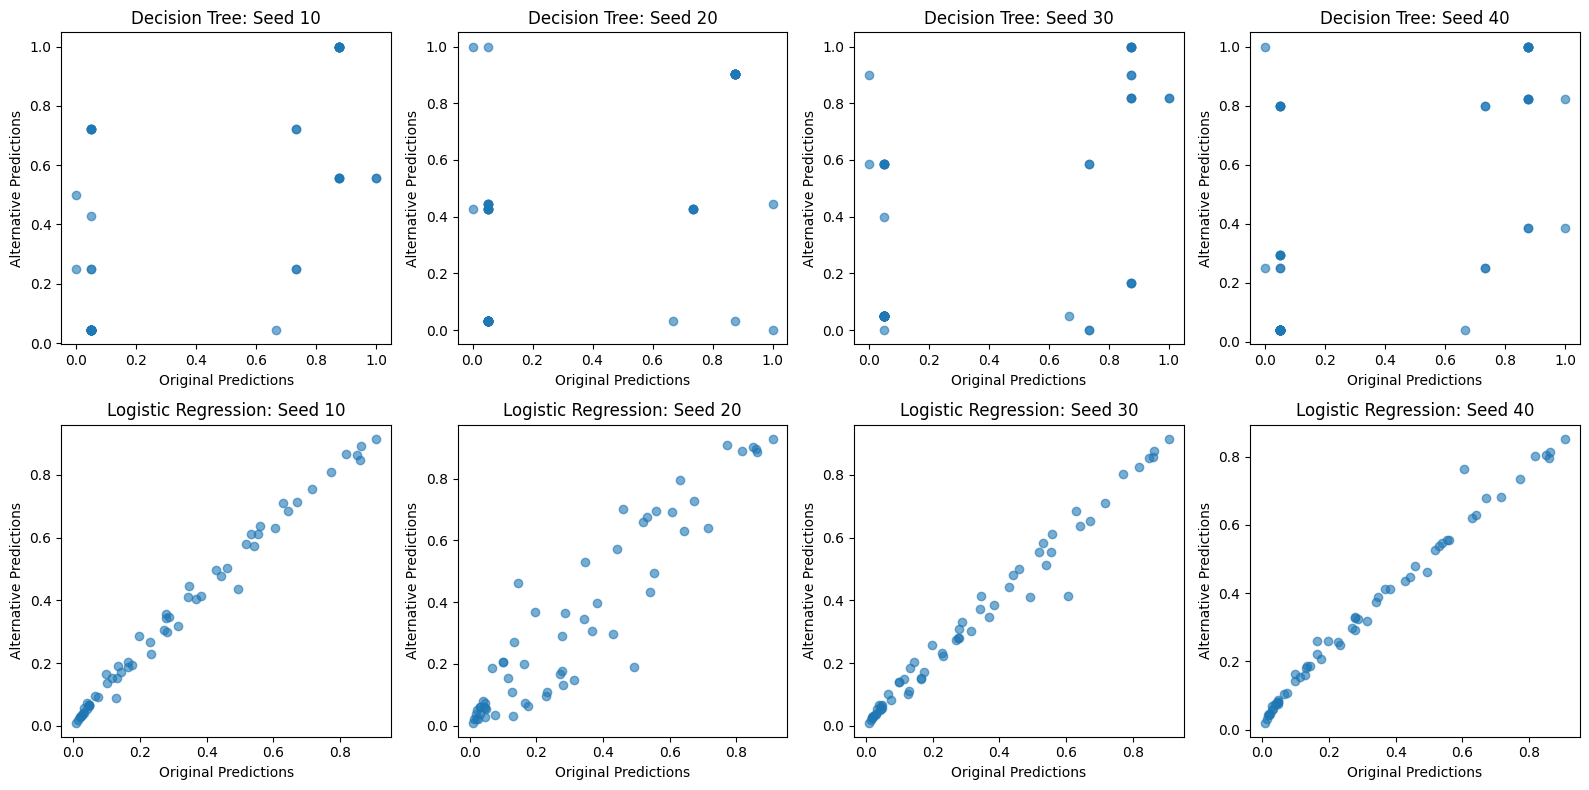

In [9]:
#Q4a
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, s in enumerate(seeds):
    axes[0, i].scatter(tree_pred, tree_preds[s], alpha=0.6)
    axes[0, i].set_title(f"Decision Tree: Seed {s}")
    axes[0, i].set_xlabel("Original Predictions")
    axes[0, i].set_ylabel("Alternative Predictions")
    axes[1, i].scatter(linear_pred, linear_preds[s], alpha=0.6)
    axes[1, i].set_title(f"Logistic Regression: Seed {s}")
    axes[1, i].set_xlabel("Original Predictions")
    axes[1, i].set_ylabel("Alternative Predictions")
plt.tight_layout()
plt.show()

The decision tree predictions do not appear very similar across different seeds, since the points are widely scattered. In contrast, the logistic regression predictions appear much more similar, with most points lying close to a straight line. Seed 20 shows more variation than the other logistic regression models.

In [11]:
#Q4b
for s in seeds:
    print("Seed:", s)
    print("Tree correlation:", pd.Series(tree_pred).corr(pd.Series(tree_preds[s])))
    print("Logistic correlation:", pd.Series(linear_pred).corr(pd.Series(linear_preds[s])))
    print()

Seed: 10
Tree correlation: 0.7298671022552139
Logistic correlation: 0.99468737523815

Seed: 20
Tree correlation: 0.6154597954949297
Logistic correlation: 0.9326947551767757

Seed: 30
Tree correlation: 0.6285004190669402
Logistic correlation: 0.9904763858966688

Seed: 40
Tree correlation: 0.6618235433455117
Logistic correlation: 0.9934953680656926



The decision tree predictions are moderately correlated, with correlations from 0.615 to 0.730. In contrast, the logistic regression predictions are highly correlated, with correlations from 0.933 to 0.995. This suggests that logistic regression produces more consistent predictions across different train/test splits.

In [14]:
#Q4c
for s in seeds:
    tree_reg = LinearRegression()
    linear_reg = LinearRegression()
    tree_reg.fit(tree_pred.reshape(-1, 1), tree_preds[s])
    linear_reg.fit(linear_pred.reshape(-1, 1), linear_preds[s])

    print("Seed:", s)
    print("Tree intercept:", tree_reg.intercept_)
    print("Tree slope:", tree_reg.coef_[0])
    print("Tree R²:", tree_reg.score(tree_pred.reshape(-1, 1), tree_preds[s]))
    print("Logistic intercept:", linear_reg.intercept_)
    print("Logistic slope:", linear_reg.coef_[0])
    print("Logistic R²:", linear_reg.score(linear_pred.reshape(-1, 1), linear_preds[s]))
    print()

Seed: 10
Tree intercept: 0.1283100374783719
Tree slope: 0.700379367444578
Tree R²: 0.5327059869544231
Logistic intercept: 0.02563161391708013
Logistic slope: 1.0207528332630076
Logistic R²: 0.9894029744581597

Seed: 20
Tree intercept: 0.1616349018375233
Tree slope: 0.5801008613684717
Tree R²: 0.37879075987066024
Logistic intercept: 0.009705000709110234
Logistic slope: 1.028183305357955
Logistic R²: 0.8699195063342653

Seed: 30
Tree intercept: 0.13803977127269604
Tree slope: 0.5962377004128053
Tree R²: 0.3950127767673184
Logistic intercept: 0.016374826286801147
Logistic slope: 0.9789600781350234
Logistic R²: 0.9810434710189267

Seed: 40
Tree intercept: 0.16534773995968832
Tree slope: 0.6603221426538732
Tree R²: 0.43801040252640866
Logistic intercept: 0.04698878119822225
Logistic slope: 0.9194659799829954
Logistic R²: 0.9870330463679863



For logistic regression, the intercepts are close to 0, the slopes are close to 1, and the R squared values are generally close to 1. As a result, their predictions are very similar across different seeds. In contrast, the decision trees have intercepts further from 0, slopes further from 1, and much lower R sqaured values. Therefore, their predictions are less consistent.

Q5:
The logistic regression models have relatively similar coefficients across different train/test splits, with most coefficients maintaining the same signs and similar values. Their predictions are also highly consistent. They have correlations from 0.933 to 0.995 and R squared values from 0.870 to 0.989. In contrast, the decision trees show noticeable differences in their splitting features and thresholds across different splits. However, their depths remain the same. Their predictions are less consistent, with correlations from 0.615 to 0.730 and R squared values from 0.379 to 0.533.

Q6:
False for this dataset. Although the decision trees have noticeably different structures across train/test splits, their predictions are not always very similar. Their correlations are from 0.615 to 0.730, and their R squared values are from 0.379 to 0.533. This indicates that there are noticeable differences in predictions. In contrast, the logistic regression models produce much more consistent predictions across different splits.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]